# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, levene, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest


In [2]:

# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')


**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:

# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Hallazgos de la carga y vista previa**

- El dataset tiene 40,000 registros y 9 columnas.
- No se observan valores nulos: todas las columnas tienen 40,000 valores no nulos.
- La columna `date` es de tipo `object` (texto) y debería ser de tipo `datetime` para poder trabajar con fechas. Se convertirá en el siguiente paso.
- Las columnas categóricas (`user_id`, `landing`, `region`, `dispositivo`, `traffic_source`, `user_type`) son de tipo `object`, lo cual es correcto.
- `converted` es de tipo `int64` (0/1) y `gasto` es de tipo `float64`, ambos adecuados para su análisis.
- En las primeras filas, `gasto` es 0 cuando `converted` es 0 y mayor que 0 cuando `converted` es 1, como indica la descripción del dataset. Esto se validará en todo el dataset más adelante.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificar usuarios únicos
print("Total de registros:", len(df))
print("Usuarios únicos:", df["user_id"].nunique())
print("Usuarios duplicados:", df["user_id"].duplicated().sum())

Total de registros: 40000
Usuarios únicos: 40000
Usuarios duplicados: 0


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Convertir a tipo fecha
df["date"] = pd.to_datetime(df["date"])

In [7]:

# Resumen estadístico
df["date"].describe()


count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [8]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [9]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [11]:
# Validar consistencia entre converted y gasto
print("Usuarios sin conversión con gasto > 0:", ((df["converted"] == 0) & (df["gasto"] > 0)).sum())
print("Usuarios con conversión y gasto <= 0:", ((df["converted"] == 1) & (df["gasto"] <= 0)).sum())

Usuarios sin conversión con gasto > 0: 0
Usuarios con conversión y gasto <= 0: 0


In [10]:
# Resumen estadístico de usuarios que se convirtieron
df[df["converted"] == 1]["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [12]:
# Explorar variables categóricas y cómo se distribuyen
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type", "converted"]:
    print(f"\nConteo de categorías: {col}")
    print(df[col].value_counts())


Conteo de categorías: landing
B    20018
A    19982
Name: landing, dtype: int64

Conteo de categorías: region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

Conteo de categorías: dispositivo
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

Conteo de categorías: traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Conteo de categorías: user_type
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

Conteo de categorías: converted
0    34294
1     5706
Name: converted, dtype: int64


In [13]:
# Balance entre las versiones A y B
print(df["landing"].value_counts(normalize=True))

B    0.50045
A    0.49955
Name: landing, dtype: float64


**Hallazgos del análisis exploratorio y revisión de calidad**

**`user_id`**
- Hay 40,000 registros y 40,000 usuarios únicos, sin duplicados. Cada fila es un usuario distinto, por lo que se cumple el supuesto de independencia de las observaciones.

**`date`**
- El experimento abarca del 2026-01-01 al 2026-01-28, es decir, 28 días con registros en cada uno (28 fechas únicas).

**`gasto`**
- Considerando a todos los usuarios, el gasto promedio es de 9.33, pero la mediana y los cuartiles son 0, porque la mayoría de los usuarios no convirtió. Por eso este resumen no sirve para comparar el gasto entre versiones.
- Entre los 5,706 usuarios que sí se convirtieron, el gasto promedio es de 65.37 y la mediana de 59.86. Va de 12.12 a 303.68.
- La media es mayor que la mediana, y el máximo (303.68) queda muy por encima del percentil 75 (80.37), lo que indica una distribución sesgada a la derecha con algunas compras altas. Estos valores son plausibles como compras reales, así que se conservan y se tendrán en cuenta al interpretar el promedio.
- Hay consistencia entre `converted` y `gasto`: ningún usuario sin conversión tiene gasto mayor a 0 y ningún usuario convertido tiene gasto de 0 o menos.
- Por lo anterior, la comparación del gasto entre A y B se hará únicamente con los usuarios que se convirtieron (`converted == 1`).

**Variables categóricas**
- Todas las columnas tienen únicamente los valores esperados, sin categorías mal escritas ni valores inesperados:
  - `landing`: A y B.
  - `region`: Norte, Centro, Sur, Occidente y Oriente. Norte es la región más grande (27.9% de los usuarios) y Oriente la más pequeña (12.0%).
  - `dispositivo`: Mobile (62.1%) y Desktop (37.9%).
  - `traffic_source`: Organic (45.0%), Ads (29.8%), Email (15.3%) y Referral (9.9%).
  - `user_type`: Nuevo (65.1%) y Recurrente (34.9%).
- El experimento está balanceado: la versión A tiene 19,982 usuarios (49.96%) y la B tiene 20,018 (50.04%).
- La tasa de conversión global es de 14.27% (5,706 de 40,000 usuarios).
- Todas las categorías tienen miles de registros, así que hay datos suficientes para las pruebas estadísticas de los siguientes pasos.

**Conclusión:** no se encontraron errores en los datos ni se requiere ninguna corrección adicional. Se continúa con el análisis.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [14]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [15]:
# Prueba de varianzas iguales (Levene)
l_stat, p_value_var = levene(gasto_A, gasto_B)
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")

alpha = 0.05  # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


### 2.1. Prueba t de Welch para comparar el gasto promedio

**Hipótesis:**

* Hipótesis nula (H₀): el gasto promedio de los usuarios que se convirtieron es igual en la página A y en la página B.
* Hipótesis alternativa (H₁): el gasto promedio de los usuarios que se convirtieron es diferente entre la página A y la página B.

* Se usa un nivel de significancia de α = 0.05.
* * Se comparan dos grupos independientes (cada usuario vio una sola versión) y la variable es numérica, por lo que corresponde una prueba t de dos muestras independientes. Como la prueba de Levene indicó varianzas diferentes entre los grupos, se usa la versión de Welch (`equal_var=False`).

In [16]:
# Aplicar prueba
# equal_var=True si Levene no encontró diferencia de varianzas, False (Welch) si la encontró
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=(p_value_var >= alpha))

# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor p: {p_value}")

Estadístico t: -9.48101092267275
Valor p: 3.627602231521493e-21


In [17]:
# Interpretar resultados
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Rechazamos la hipótesis nula: hay evidencia de una diferencia.


In [18]:
# Calcular promedios
media_A = gasto_A.mean()
media_B = gasto_B.mean()

print('El gasto promedio en la página A es: ', media_A)
print('El gasto promedio en la página B es: ', media_B)
print('La diferencia (A - B) es de: ', media_A - media_B)

El gasto promedio en la página A es:  61.0865724522293
El gasto promedio en la página B es:  68.74536005009392
La diferencia (A - B) es de:  -7.658787597864624


### 2.2. 📝 Conclusión e interpretación

**Decisión:**

Se **rechaza la hipótesis nula**. El valor p (≈ 3.6 × 10⁻²¹) es muchísimo menor que el nivel de significancia de 0.05, por lo que hay evidencia estadística de que el gasto promedio de los usuarios que se convirtieron no es igual en la página A y en la página B.

**Interpretación de negocio:**

- Entre los usuarios que compraron, el gasto promedio en la página B (68.75) es mayor que en la página A (61.09). La diferencia es de 7.66 por cliente, aproximadamente 12.5% más que en A.
- El estadístico t es negativo (-9.48) porque la prueba resta A menos B. Solo indica que A queda por debajo de B, y no significa que haya un error.
- Con una diferencia de este tamaño y miles de clientes por grupo, es muy poco probable que se deba al azar. Los clientes que llegan por la página B tienden a gastar más en cada compra.
- Si lo único que se mirara fuera el valor económico por cliente convertido, la página B sería la mejor opción.

**Limitaciones:**

- Esta comparación solo incluye a los usuarios que se convirtieron. Todavía no dice cuántos usuarios compran en cada página, que es la tasa de conversión y se evalúa en el siguiente paso. La decisión final debe considerar ambas métricas.
- El resultado se basa en una muestra de usuarios y en un periodo de 28 días (enero de 2026).
- El gasto tiene una distribución sesgada a la derecha, con algunas compras altas que pueden influir en el promedio. Con tantos datos la prueba es robusta, pero conviene tenerlo presente.
- La significancia estadística no garantiza causalidad ni importancia práctica por sí sola: el negocio debe valorar si una diferencia de 7.66 por cliente justifica implementar el cambio.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### 3.1. Prueba z para comparar tasas de conversión

**Hipótesis:**

* Hipótesis nula (H₀): la tasa de conversión es igual en la página A y en la página B.
* Hipótesis alternativa (H₁): la tasa de conversión es diferente entre la página A y la página B.

* Se usa un nivel de significancia de α = 0.05.
* La variable `converted` es binaria (convirtió o no) y lo que se compara es una proporción entre dos grupos independientes, por lo que corresponde una prueba z para proporciones.

In [19]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [20]:
# Pasar los valores a formato lista
exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'], totales['B']]

In [21]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos, observaciones)

# Visualizar resultados
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

Estadístico z: -9.677362674655983
Valor p: 3.7629765627523803e-22


In [22]:
# Interpretar resultados
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Rechazamos la hipótesis nula: hay evidencia de una diferencia.


In [23]:
# Obtener tasa o porcentaje de éxito por página
tasa_A = exitos[0] / observaciones[0]
tasa_B = exitos[1] / observaciones[1]

print(f"Tasa de conversión página A: {tasa_A:.2%}")
print(f"Tasa de conversión página B: {tasa_B:.2%}")

# Interpretar dirección de resultados
if tasa_A > tasa_B:
    print(f"\nLa página A tiene una mayor tasa de conversión ({tasa_A - tasa_B:.2%}).")
elif tasa_B > tasa_A:
    print(f"\nLa página B tiene una mayor tasa de conversión ({tasa_B - tasa_A:.2%}).")
else:
    print("\nAmbas páginas tienen la misma tasa de conversión.")

Tasa de conversión página A: 12.57%
Tasa de conversión página B: 15.96%

La página B tiene una mayor tasa de conversión (3.38%).


### 3.2. 📝 Conclusión e interpretación

**Decisión:**

Se **rechaza la hipótesis nula**. El valor p (≈ 3.8 × 10⁻²²) es mucho menor que el nivel de significancia de 0.05, por lo que hay evidencia estadística de que la tasa de conversión no es igual en la página A y en la página B.

**Interpretación de negocio:**

- La página B convierte más usuarios que la página A: 15.96% (3,194 de 20,018 usuarios) frente a 12.57% (2,512 de 19,982 usuarios).
- La diferencia es de 3.38 puntos porcentuales, lo que equivale a aproximadamente un 27% más de conversiones en términos relativos. En otras palabras, por cada 100 usuarios que ven la página B se convierten alrededor de 3 más que con la página A.
- El estadístico z es negativo (-9.68) porque la prueba resta A menos B. Solo indica que A queda por debajo de B.
- Los grupos tienen casi el mismo tamaño y miles de usuarios cada uno, por lo que es muy poco probable que la diferencia se deba al azar.
- Este resultado va en la misma dirección que el análisis del gasto: la página B logra que más usuarios se conviertan en clientes y, además, estos clientes gastan en promedio más.

**Limitaciones:**

- El resultado se basa en una muestra de usuarios y en un periodo de 28 días (enero de 2026).
- La conversión se mide como un evento binario (convirtió o no) y se asume que las observaciones son independientes, lo cual se verificó al comprobar que cada `user_id` aparece una sola vez.
- La prueba indica que existe una diferencia, pero no explica por qué la página B funciona mejor, y no evalúa si la mejora justifica los costos de implementarla.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### 4.1. Prueba chi-cuadrada de independencia

**Hipótesis:**

* Hipótesis nula (H₀): la conversión es independiente de la fuente de tráfico (no existe relación entre ambas variables).
* Hipótesis alternativa (H₁): la conversión depende de la fuente de tráfico (sí existe relación entre ambas variables).

* Se usa un nivel de significancia de α = 0.05.
* Las dos variables son categóricas (`traffic_source` con 4 categorías y `converted` binaria), por lo que corresponde una prueba chi-cuadrada de independencia sobre una tabla de contingencia con conteos.

In [24]:
# Tabla de contingencia (conteos)
tabla = pd.crosstab(df['traffic_source'], df['converted'])
tabla

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [25]:

# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

# Visualizar resultados
print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor p: {p_value}")
print(f"Grados de libertad: {dof}")


Estadístico chi-cuadrado: 8.662108841397938
Valor p: 0.0341375947833914
Grados de libertad: 3


In [26]:
# Verificar frecuencias esperadas (deben ser >= 5)
expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns)
print(expected_df)
print("\nCeldas con frecuencia esperada < 5:", (expected < 5).sum())

converted                 0           1
traffic_source                         
Ads             10232.47225  1702.52775
Email            5249.55405   873.44595
Organic         15421.15445  2565.84555
Referral         3390.81925   564.18075

Celdas con frecuencia esperada < 5: 0


In [27]:
# Interpretar resultados
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.


In [28]:
# Tabla de contingencia normalizada (% de conversión por fuente de tráfico)
print(pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100)

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


In [29]:
# Fuerza de la asociación (V de Cramér)
n = tabla.values.sum()
v_cramer = (chi2_stat / (n * (min(tabla.shape) - 1))) ** 0.5
print(f"V de Cramér: {v_cramer:.3f}")

V de Cramér: 0.015


### 4.2. 📝 Conclusión e interpretación

**Decisión:**

Se **rechaza la hipótesis nula**. El valor p (≈ 0.034) es menor que el nivel de significancia de 0.05, por lo que hay evidencia estadística de que la conversión está asociada a la fuente de tráfico. Se verificó el supuesto de frecuencias esperadas: ninguna celda tiene un valor esperado menor a 5.

**Interpretación de negocio:**

*Cantidades absolutas (volumen de conversiones):*
- **Organic** aporta la mayor cantidad de usuarios convertidos (2,480, aproximadamente 43% del total), seguido de **Ads** (1,759, 31%), **Email** (918, 16%) y **Referral** (549, 10%).
- Esto se debe en gran parte al tamaño de cada canal: Organic es también el que más usuarios trae (17,987).

*Tasas de conversión (eficiencia de cada canal):*
- **Email** (14.99%) y **Ads** (14.74%) convierten ligeramente mejor que **Referral** (13.88%) y **Organic** (13.79%).
- Es decir, Organic aporta más clientes por volumen, pero no es el canal que mejor convierte; Email y Ads son más eficientes por usuario.

*Qué tan grande es la asociación:*
- La diferencia entre el canal que mejor convierte y el que peor convierte es de aproximadamente 1.2 puntos porcentuales. Aunque es estadísticamente significativa, el efecto es pequeño (V de Cramér ≈ 0.015), por lo que la fuente de tráfico explica muy poco de la decisión de comprar.
- El valor p está relativamente cerca del umbral de 0.05, así que la evidencia es moderada y no contundente.

**Limitaciones:**

- Una asociación estadística no implica causalidad: no se sabe si el canal provoca la conversión o si llegan perfiles de usuarios distintos por cada canal.
- El análisis no considera el costo de cada canal (por ejemplo, la inversión en Ads), por lo que no basta para decidir dónde invertir.
- El resultado se basa en una muestra de usuarios y en un periodo de 28 días (enero de 2026).


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### 5.1. Prueba chi-cuadrada de independencia

**Hipótesis:**

* Hipótesis nula (H₀): la conversión es independiente del tipo de usuario (no existe relación entre ambas variables).
* Hipótesis alternativa (H₁): la conversión depende del tipo de usuario (sí existe relación entre ambas variables).

* Se usa un nivel de significancia de α = 0.05.
* Las dos variables son categóricas (`user_type` con 2 categorías y `converted` binaria), por lo que corresponde una prueba chi-cuadrada de independencia sobre una tabla de contingencia con conteos.

In [30]:
# Tabla de contingencia (conteos)
tabla = pd.crosstab(df['user_type'], df['converted'])
tabla

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [31]:
# Tabla de contingencia normalizada (% de conversión por tipo de usuario)
print(pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100)

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


In [32]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

# Visualizar resultados
print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor p: {p_value}")
print(f"Grados de libertad: {dof}")

Estadístico chi-cuadrado: 0.5134849494478645
Valor p: 0.4736341272301974
Grados de libertad: 1


In [33]:
# Verificar frecuencias esperadas (deben ser >= 5)
expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns)
print(expected_df)
print("\nCeldas con frecuencia esperada < 5:", (expected < 5).sum())

converted             0           1
user_type                          
Nuevo       22319.39255  3713.60745
Recurrente  11974.60745  1992.39255

Celdas con frecuencia esperada < 5: 0


In [34]:
# Interpretar resultados
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


In [35]:
# Fuerza de la asociación (V de Cramér)
n = tabla.values.sum()
v_cramer = (chi2_stat / (n * (min(tabla.shape) - 1))) ** 0.5
print(f"V de Cramér: {v_cramer:.3f}")

V de Cramér: 0.004


### 5.2. 📝 Conclusión e interpretación

**Decisión:**

**No se rechaza la hipótesis nula**. El valor p (≈ 0.47) es mayor que el nivel de significancia de 0.05, por lo que no hay evidencia estadística suficiente de que la conversión esté asociada al tipo de usuario. Se verificó el supuesto de frecuencias esperadas: ninguna celda tiene un valor esperado menor a 5.

**Interpretación de negocio:**

- Los usuarios nuevos y los recurrentes convierten prácticamente igual: 14.36% (3,738 de 26,033 usuarios) frente a 14.09% (1,968 de 13,967 usuarios). La diferencia es de apenas 0.27 puntos porcentuales y es compatible con el azar.
- La V de Cramér (≈ 0.004) confirma que la asociación entre el tipo de usuario y la conversión es prácticamente nula.
- Los usuarios nuevos aportan más clientes en total (alrededor del 65% de las conversiones), pero eso se debe a que son más numerosos (65% de los usuarios), no a que conviertan mejor.
- Haber visitado antes la página no hace más probable que el usuario compre en esta ocasión. Con base en la conversión, no hay razón para tratar de forma distinta a ambos perfiles ni para segmentar la página por tipo de usuario.

**Limitaciones:**

- No rechazar la hipótesis nula no demuestra que las tasas sean idénticas, solo que los datos no muestran una diferencia detectable.
- Este análisis solo evalúa la conversión. No se revisó si el gasto o el comportamiento difieren entre usuarios nuevos y recurrentes.
- No se analizó si el efecto de la página A o B cambia según el tipo de usuario, solo la relación entre el tipo de usuario y la conversión.
- El resultado se basa en una muestra de usuarios y en un periodo de 28 días (enero de 2026).

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [36]:
# Tabla de contingencia normalizada (% de usuarios por fuente de tráfico)
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
tabla_trafico

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


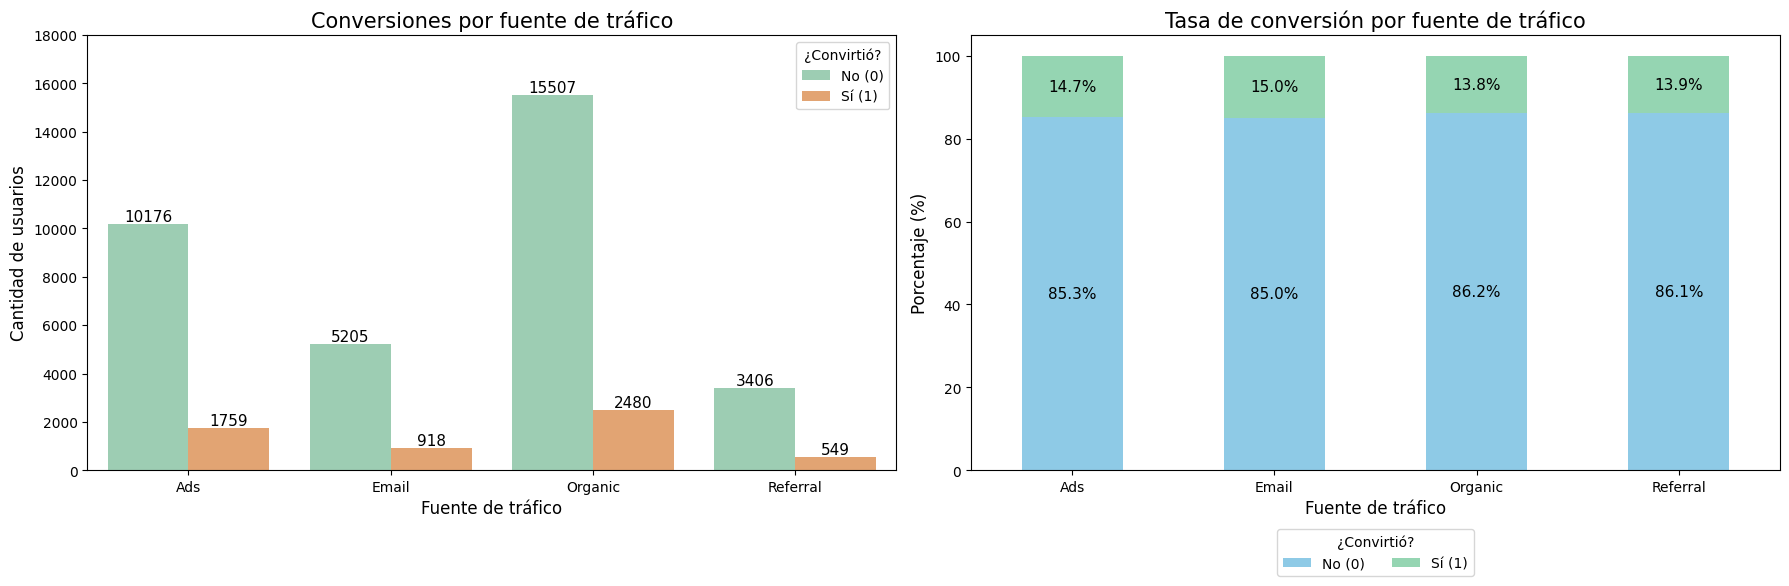

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Barras agrupadas (cantidades)
# -----------------------------
sns.countplot(data=df, x='traffic_source', hue='converted', order=tabla_trafico.index,
              palette=["#95D5B2", "#F4A261"], ax=axes[0])

for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].text(x=bar.get_x() + bar.get_width() / 2,
                 y=height,
                 s=int(height),
                 ha='center',
                 va='bottom',
                 fontsize=11)

axes[0].set_title('Conversiones por fuente de tráfico', fontsize=15)
axes[0].set_xlabel('Fuente de tráfico', fontsize=12)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=12)
axes[0].set_ylim(0, 18000)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

# Barras apiladas (proporciones)
# -----------------------------
tabla_trafico.plot(kind='bar', stacked=True, color=["#8ecae6", "#95d5b2"], ax=axes[1])

for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].text(x=bar.get_x() + bar.get_width() / 2,
                 y=bar.get_y() + height / 2,
                 s=f"{height:.1f}%",
                 ha='center',
                 va='center',
                 fontsize=11)

axes[1].set_title('Tasa de conversión por fuente de tráfico', fontsize=15)
axes[1].set_xlabel('Fuente de tráfico', fontsize=12)
axes[1].set_ylabel('Porcentaje (%)', fontsize=12)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper center',
               bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

**Qué muestra el gráfico:**

- **Gráfico de la izquierda (cantidades):** muestra cuántos usuarios convirtieron y no convirtieron en cada fuente de tráfico. Organic es el canal con más usuarios y más conversiones (2,480), seguido de Ads (1,759), Email (918) y Referral (549). En todos los canales los usuarios que no convierten son mucho más numerosos que los que sí lo hacen.
- **Gráfico de la derecha (proporciones):** muestra qué porcentaje de cada canal convirtió y qué porcentaje no. Email (15.0%) y Ads (14.7%) tienen una tasa ligeramente mayor que Referral (13.9%) y Organic (13.8%).
- Las dos vistas cuentan historias distintas: Organic aporta más clientes por su volumen, pero Email y Ads son más eficientes por usuario.
- En el gráfico de proporciones, la parte de usuarios convertidos se ve casi igual de alta en los cuatro canales (diferencia de aproximadamente 1.2 puntos porcentuales). Esto refuerza el resultado de la prueba chi-cuadrada: la asociación existe, pero es débil (V de Cramér ≈ 0.015).

### Relación entre el tipo de usuario y la conversión

In [38]:
# Tabla de contingencia normalizada (% de usuarios por tipo de usuario)
tabla_usuario = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
tabla_usuario

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


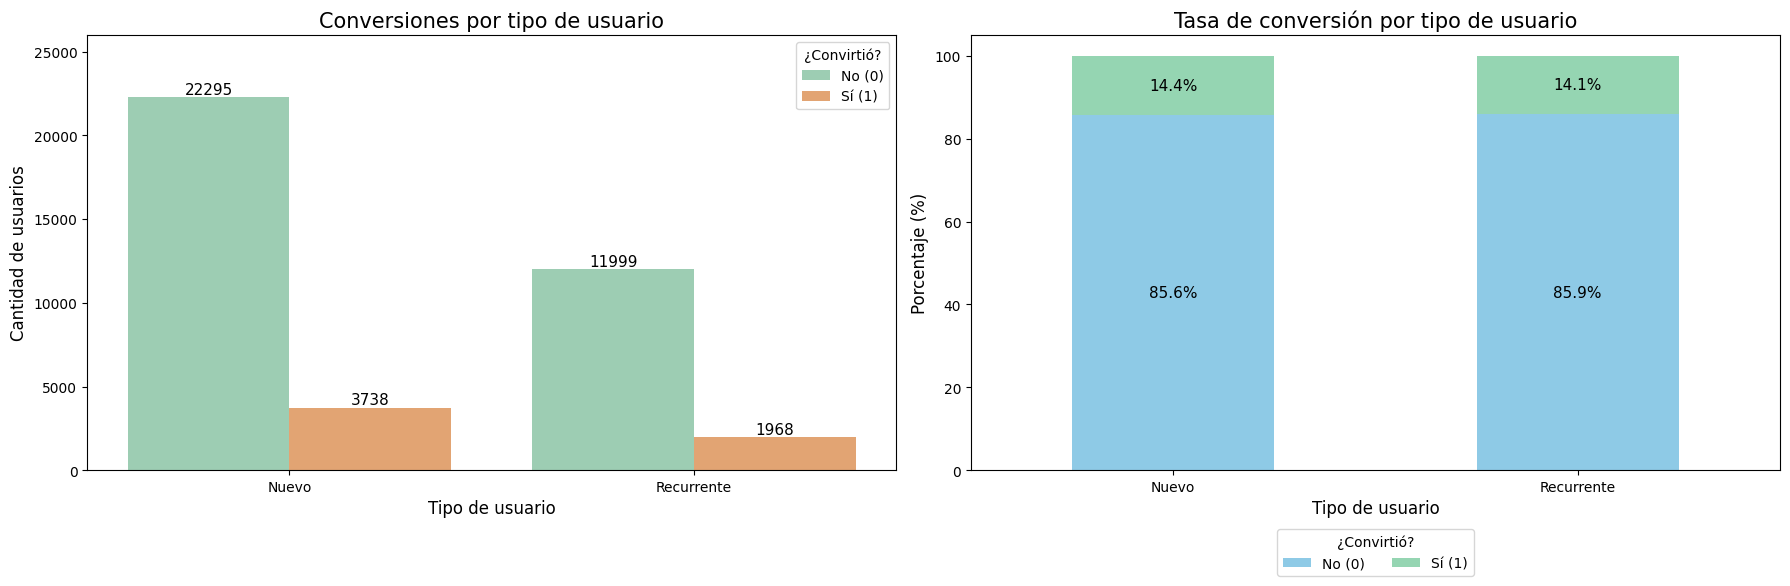

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Barras agrupadas (cantidades)
# -----------------------------
sns.countplot(data=df, x='user_type', hue='converted', order=tabla_usuario.index,
              palette=["#95D5B2", "#F4A261"], ax=axes[0])

for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].text(x=bar.get_x() + bar.get_width() / 2,
                 y=height,
                 s=int(height),
                 ha='center',
                 va='bottom',
                 fontsize=11)

axes[0].set_title('Conversiones por tipo de usuario', fontsize=15)
axes[0].set_xlabel('Tipo de usuario', fontsize=12)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=12)
axes[0].set_ylim(0, 26000)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

# Barras apiladas (proporciones)
# -----------------------------
tabla_usuario.plot(kind='bar', stacked=True, color=["#8ecae6", "#95d5b2"], ax=axes[1])

for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].text(x=bar.get_x() + bar.get_width() / 2,
                 y=bar.get_y() + height / 2,
                 s=f"{height:.1f}%",
                 ha='center',
                 va='center',
                 fontsize=11)

axes[1].set_title('Tasa de conversión por tipo de usuario', fontsize=15)
axes[1].set_xlabel('Tipo de usuario', fontsize=12)
axes[1].set_ylabel('Porcentaje (%)', fontsize=12)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper center',
               bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

**Qué muestra el gráfico:**

- **Gráfico de la izquierda (cantidades):** muestra cuántos usuarios convirtieron y no convirtieron según el tipo de usuario. Los usuarios nuevos son más numerosos y aportan más conversiones (3,738) que los recurrentes (1,968).
- **Gráfico de la derecha (proporciones):** muestra qué porcentaje de cada tipo de usuario convirtió. Las tasas son prácticamente iguales: 14.4% en usuarios nuevos y 14.1% en recurrentes.
- Los usuarios nuevos aportan más clientes porque son más, no porque conviertan mejor. Las barras de proporciones se ven casi idénticas, lo que refuerza el resultado de la prueba chi-cuadrada: no hay evidencia de asociación entre el tipo de usuario y la conversión (V de Cramér ≈ 0.004).

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders
Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario.
Preguntas a responder:

¿Qué página genera mayor conversión y gasto promedio?
¿Qué canales de tráfico son más efectivos para generar conversiones?
¿Existen diferencias significativas según el tipo de usuario?
¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?

## 🌟 Insight Ejecutivo basado en el Experimento A/B
Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario.
Preguntas a responder:

¿Qué página genera mayor conversión y gasto promedio?
¿Qué canales de tráfico son más efectivos para generar conversiones?
¿Existen diferencias significativas según el tipo de usuario?
¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?
### 🔍 Comparación de página (A vs B)

**Gasto promedio por usuario que convirtió:**

* El gasto promedio en la página B (68.75) es mayor que en la página A (61.09), una diferencia de 7.66 por cliente (aproximadamente 12.5% más).
* La prueba t de Welch indica que la diferencia es estadísticamente significativa (p ≈ 3.6 × 10⁻²¹).
* **Interpretación:** los clientes que llegan por la página B gastan más en cada compra, y es muy poco probable que se deba al azar.

**Tasa de conversión:**

* La página B convierte 15.96% de sus usuarios (3,194 de 20,018) frente a 12.57% de la página A (2,512 de 19,982).
* La diferencia es de 3.38 puntos porcentuales (aproximadamente 27% más conversiones en términos relativos) y es estadísticamente significativa según la prueba z (p ≈ 3.8 × 10⁻²²).
* **Interpretación:** la página B logra que más usuarios se conviertan en clientes. Junto con el resultado anterior, B es mejor en las dos métricas del experimento: convierte más y cada cliente gasta más.

### 🌐 Canales de tráfico

* Organic aporta el mayor volumen de conversiones (2,480, 43% del total), seguido de Ads (1,759, 31%), Email (918, 16%) y Referral (549, 10%).
* En eficiencia, Email (15.0%) y Ads (14.7%) convierten ligeramente mejor que Referral (13.9%) y Organic (13.8%).
* La asociación entre canal y conversión es estadísticamente significativa (p ≈ 0.034), pero débil (V de Cramér ≈ 0.015): la diferencia entre el mejor y el peor canal es de aproximadamente 1.2 puntos porcentuales.
* **Interpretación:** Organic es el canal más importante por volumen, mientras que Email y Ads son un poco más eficientes por usuario. Como las diferencias de tasa son pequeñas y no se evaluó el costo de cada canal, estos resultados no bastan por sí solos para reasignar presupuesto.

### 👤 Tipo de usuario

* Los usuarios nuevos (14.36%) y los recurrentes (14.09%) convierten prácticamente igual. No hay evidencia de asociación entre el tipo de usuario y la conversión (p ≈ 0.47; V de Cramér ≈ 0.004).
* Los usuarios nuevos aportan cerca del 65% de las conversiones porque son más numerosos, no porque conviertan mejor.
* **Interpretación:** con base en la conversión, no hay razón para diseñar una experiencia distinta por tipo de usuario.

### ✅ Recomendaciones

1. **Implementar la página B para todos los usuarios.** Mejora tanto la conversión como el gasto promedio por cliente, con evidencia estadística sólida en ambas métricas.
2. **Mantener la inversión en el tráfico orgánico**, que es la mayor fuente de clientes, y **evaluar con datos de costo** si conviene reforzar Email y Ads, que convierten un poco mejor. La diferencia observada es pequeña por sí sola.
3. **No segmentar la página por tipo de usuario**, porque no se observaron diferencias en la conversión.
4. **Dar seguimiento tras la implementación** y, como siguiente paso, revisar si el beneficio de B se mantiene en cada canal, dispositivo y región. Este análisis no lo evaluó.

**Limitaciones:** el análisis se basa en una muestra de 40,000 usuarios durante 28 días (enero de 2026). Los resultados muestran asociaciones y diferencias entre versiones, pero no explican por qué B funciona mejor ni incluyen costos de implementación o de cada canal.